In [1]:
pip install fastparquet

Defaulting to user installation because normal site-packages is not writeable


Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

stations_toulouse = pd.read_parquet("stations_toulouse.parquet")
stations_toulouse

,station,longitude,latitude,station_id
0,00001 - POIDS DE L'HUILE,1.445475,43.604190,0
1,00002 - LAFAYETTE,1.445306,43.604885,1
2,00003 - ALSACE - LORRAINE - POMME,1.445454,43.603302,2
3,00003 - ALSACE-LORRAINE - POMME,1.445454,43.603302,3
4,00003 - POMME,1.445454,43.603302,4
...,...,...,...,...
858,TOLOSANE - PASTOURELLES,1.477417,43.543115,858
859,TOLOSANE - POUCIQUOT,1.469875,43.551101,859
860,TOURNEFEUILLE MAIRIE,1.346042,43.583665,860
861,VELASQUEZ - TAMARIS,1.390347,43.621004,861


In [3]:
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")
history_toulouse_train

bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9
                         2023-08-05 12:30:00     10       9
                         2023-08-05 12:45:00     10       9
                         2023-08-05 13:00:00     11       8
                         2023-08-05 13:15:00     11       8
...                                             ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3
                         2026-02-12 15:15:00      0       3
                         2026-02-12 15:30:00      0       3
                         2026-02-12 15:45:00      0       3
                         2026-02-12 16:00:00      0       3

[40012622 rows x 2 columns]

In [1]:
for i in range(800):
    if history_toulouse_train.loc[index[i]]

SyntaxError: expected ':' (3080002537.py, line 2)

In [4]:
history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")
history_toulouse_test

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min
station,commit_at,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00002 - LAFAYETTE,2026-07-31 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - POMME,2025-01-05 05:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PASTEUR - LAVOISIER,2025-08-05 10:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
import numpy as np 
# Utilisation de groupby

# Récupèration de la dernière date de mesure pour chaque station
# des données d'entraînement
last = (
    history_toulouse_train
    .groupby(level="station")
    .mean()
    .copy()
    .round()
)

last


,bikes,stands
station,,
00001 - POIDS DE L'HUILE,6.0,12.0
00002 - LAFAYETTE,10.0,14.0
00003 - ALSACE - LORRAINE - POMME,4.0,12.0
00003 - ALSACE-LORRAINE - POMME,6.0,11.0
00003 - POMME,10.0,11.0
...,...,...
NARBONNE - CLOTASSES,0.0,6.0
PASTEUR - LAVOISIER,0.0,0.0
PLACE GEORGES BRASSENS,0.0,0.0


In [9]:
import numpy as np 
last = (
        history_toulouse_train
        .groupby(level="station")
        .tail(300)
        .copy()
    )
last

bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2026-07-28 19:00:00     13       6
                         2026-07-28 19:15:00     13       6
                         2026-07-28 19:30:00     13       6
                         2026-07-28 19:45:00     13       6
                         2026-07-28 20:00:00      8      10
...                                             ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3
                         2026-02-12 15:15:00      0       3
                         2026-02-12 15:30:00      0       3
                         2026-02-12 15:45:00      0       3
                         2026-02-12 16:00:00      0       3

[238762 rows x 2 columns]

In [10]:
import numpy as np 
# Utilisation de groupby

# Récupèration de la dernière date de mesure pour chaque station
# des données d'entraînement
moyt = (
    last
    .groupby(level="station")
    .mean()
    .copy()
    .round()
)
moyt

,bikes,stands
station,,
00001 - POIDS DE L'HUILE,6.0,13.0
00002 - LAFAYETTE,8.0,13.0
00003 - ALSACE - LORRAINE - POMME,5.0,12.0
00003 - ALSACE-LORRAINE - POMME,6.0,11.0
00003 - POMME,17.0,0.0
...,...,...
NARBONNE - CLOTASSES,0.0,16.0
PASTEUR - LAVOISIER,0.0,0.0
PLACE GEORGES BRASSENS,0.0,0.0


In [11]:
import numpy as np 
# Utilisation de groupby

# Récupèration de la dernière date de mesure pour chaque station
# des données d'entraînement
moyh = (
    history_toulouse_train
    .groupby(level="station")
    .mean()
    .copy()
    .round()
)
moyh

,bikes,stands
station,,
00001 - POIDS DE L'HUILE,6.0,12.0
00002 - LAFAYETTE,10.0,14.0
00003 - ALSACE - LORRAINE - POMME,4.0,12.0
00003 - ALSACE-LORRAINE - POMME,6.0,11.0
00003 - POMME,10.0,11.0
...,...,...
NARBONNE - CLOTASSES,0.0,6.0
PASTEUR - LAVOISIER,0.0,0.0
PLACE GEORGES BRASSENS,0.0,0.0


In [12]:
history_toulouse_naivemed_TurboTurtles = history_toulouse_test.copy()
history_toulouse_naivemed_TurboTurtles

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min
station,commit_at,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00002 - LAFAYETTE,2026-07-31 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - POMME,2025-01-05 05:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PASTEUR - LAVOISIER,2025-08-05 10:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
history_toulouse_moyt_station_TurboTurtles = history_toulouse_test.copy()
history_toulouse_moyt_station_TurboTurtles

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min
station,commit_at,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00002 - LAFAYETTE,2026-07-31 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - POMME,2025-01-05 05:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PASTEUR - LAVOISIER,2025-08-05 10:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
for i in range(800) :
    history_toulouse_naivemed_TurboTurtles.loc[last.index[i]] = last["bikes"].values[i]
history_toulouse_naivemed_TurboTurtles

/tmp/cache-apacher/ipykernel_810944/1833716160.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  history_toulouse_naivemed_TurboTurtles.loc[last.index[i]] = last["bikes"].values[i]
/tmp/cache-apacher/ipykernel_810944/1833716160.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  history_toulouse_naivemed_TurboTurtles.loc[last.index[i]] = last["bikes"].values[i]
/tmp/cache-apacher/ipykernel_810944/1833716160.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many time

/tmp/cache-apacher/ipykernel_810944/1833716160.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  history_toulouse_naivemed_TurboTurtles.loc[last.index[i]] = last["bikes"].values[i]
/tmp/cache-apacher/ipykernel_810944/1833716160.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  history_toulouse_naivemed_TurboTurtles.loc[last.index[i]] = last["bikes"].values[i]
/tmp/cache-apacher/ipykernel_810944/1833716160.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many time

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min,2026-07-28 19:00:00,2026-07-28 19:15:00,...,2025-11-09 08:30:00,2025-11-09 08:45:00,2025-11-09 09:00:00,2025-11-09 09:15:00,2025-11-09 09:30:00,2025-11-09 09:45:00,2025-11-09 10:00:00,2025-11-09 10:15:00,2025-11-09 10:30:00,2025-11-09 10:45:00
station,commit_at,,,,,,,,,,,,,,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00002 - LAFAYETTE,2026-07-31 23:45:00,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,2.0,2.0,3.0,2.0,2.0,4.0,3.0,3.0,2.0
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - POMME,2025-01-05 05:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PASTEUR - LAVOISIER,2025-08-05 10:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
history_toulouse_naivemed_TurboTurtles.to_parquet("history_toulouse_naivemed_TurboTurtles.parquet", index=True)

/opt/local/stow/conda/miniforge3/envs/cremi-trixie-py3.13/lib/python3.13/site-packages/pandas/io/parquet.py:191: UserWarning: The DataFrame has column names of mixed type. They will be converted to strings and not roundtrip correctly.
  table = self.api.Table.from_pandas(df, **from_pandas_kwargs)


In [16]:
df = history_toulouse_train.copy()

dates = df.index.get_level_values("commit_at")

df



bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9
                         2023-08-05 12:30:00     10       9
                         2023-08-05 12:45:00     10       9
                         2023-08-05 13:00:00     11       8
                         2023-08-05 13:15:00     11       8
...                                             ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3
                         2026-02-12 15:15:00      0       3
                         2026-02-12 15:30:00      0       3
                         2026-02-12 15:45:00      0       3
                         2026-02-12 16:00:00      0       3

[40012622 rows x 2 columns]

In [18]:
df["heure_minute"] = dates.strftime("%H:%M")


moy_velos_quart_heure = (
    df
    .groupby(["station", "heure_minute"])[["bikes"]]
    .mean()
    .round()
)
moy_velos_quart_heure


bikes
station                  heure_minute       
00001 - POIDS DE L'HUILE 00:00           2.0
                         00:15           2.0
                         00:30           2.0
                         00:45           2.0
                         01:00           2.0
...                                      ...
TEST BEE                 22:45           1.0
                         23:00           1.0
                         23:15           1.0
                         23:30           1.0
                         23:45           1.0

[76528 rows x 1 columns]

In [25]:
for i in range(800) :
    history_toulouse_moyt_station_TurboTurtles.loc[moyt.index[i]] = moyt["bikes"].values[i]
history_toulouse_moyt_station_TurboTurtles

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min
station,commit_at,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0
00002 - LAFAYETTE,2026-07-31 23:45:00,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0
00003 - POMME,2025-01-05 05:45:00,17.0,17.0,17.0,17.0,17.0,17.0,17.0,17.0
...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PASTEUR - LAVOISIER,2025-08-05 10:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
history_toulouse_moyt_station_TurboTurtles.to_parquet("history_toulouse_moyt_station_TurboTurtles.parquet", index=True)

In [19]:
last_9 = (
    history_toulouse_train
    .groupby(level="station")
    .tail(9)
    .copy()
)
last_9

bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2026-07-31 19:45:00      6      10
                         2026-07-31 20:00:00      1      15
                         2026-07-31 20:15:00      1      15
                         2026-07-31 20:30:00      1      15
                         2026-07-31 20:45:00      1      15
...                                             ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3
                         2026-02-12 15:15:00      0       3
                         2026-02-12 15:30:00      0       3
                         2026-02-12 15:45:00      0       3
                         2026-02-12 16:00:00      0       3

[7189 rows x 2 columns]

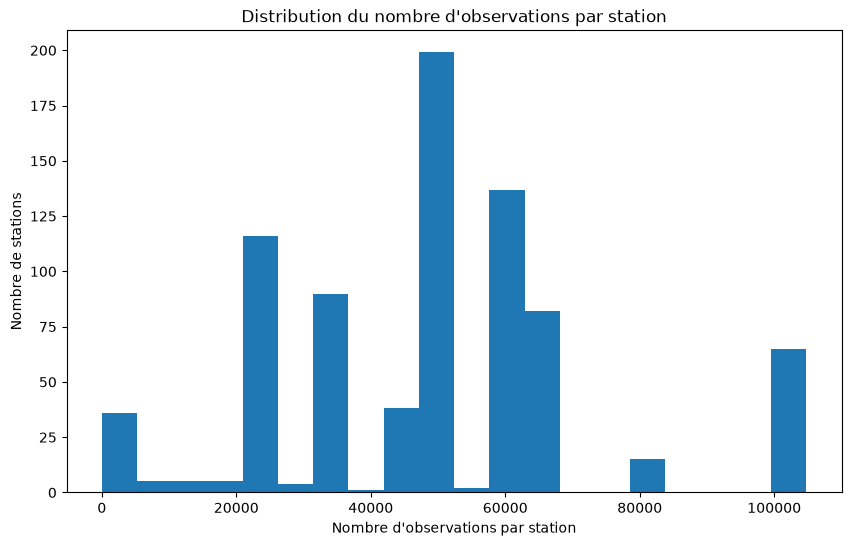

In [24]:
nb_obs = (
    history_toulouse_train
    .groupby(level="station")
    .count()
)
vect_nb_obs = nb_obs["bikes"]

plt.figure(figsize=(10, 6))

plt.hist(vect_nb_obs, bins=20)

plt.xlabel("Nombre d'observations par station")
plt.ylabel("Nombre de stations")
plt.title("Distribution du nombre d'observations par station")

plt.show()